# Exercice
Application d'une methode de clustering pour la segmentation d'images sous la forme de color quantization (réduction de palette de couleurs)  sur une photo de trump
on utilise kmeans avec c=16 et on affiche l'image resultats en affectant a chaque pixel la couleur du centre dont il est le plus proche. 

indice: 
- pour recuperer les valeurs (couleur) des centres dees classes, vous pouez utiliser ".cluster_centers_" sur le modele k-means ( une fois le modele entrain")
- pour recuperer les labels, on utilise "labels_" sur k-means
- exemple : 
  - inconnu = plt.imread('i.png')
  -  plt.imshow(inconnu) 
  -  w, h, d = inconnu.shape
  -  x = np.reshape(inconnu, (w*h,d))
- une fois image de trump segmentée (quantifiée avec 16 couleurs)


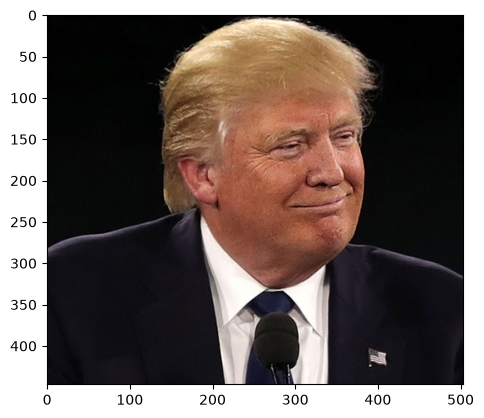

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# reading the image
trump = plt.imread("Trump.png")
plt.imshow(trump)

In [36]:
w, h, d = trump.shape
X = np.reshape(trump,(w*h,d))
print(X)

[[0.00784314 0.01568628 0.01176471]
 [0.00784314 0.01568628 0.01176471]
 [0.00784314 0.01568628 0.01176471]
 ...
 [0.03921569 0.03529412 0.05490196]
 [0.03921569 0.03529412 0.05490196]
 [0.04313726 0.03921569 0.05882353]]


here its in two dimensions in order to be processed by an ML model

d = 3 because we have RGB


## K-means

In [37]:
# entrainement de k-means 
from sklearn import cluster
kmeans = cluster.KMeans(n_clusters=16)
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",16
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float32](16, 3)

- pour recuperer les valeurs (couleur) des centres dees classes, vous pouez utiliser ".cluster_centers_" sur le modele k-means ( une fois le modele entrain")
- pour recuperer les labels, on utilise "labels_" sur k-means

In [38]:
# recuperationn des valeurs des centres de classe
centroids_values = kmeans.cluster_centers_
print(len(centroids_values))


16


In [39]:
color_labels = kmeans.labels_
print(color_labels)

[0 0 0 ... 8 8 8]


In [40]:
# retrieve for each pixel the cluster it belongs to
X_segmented = centroids_values[color_labels]
print(X_segmented)

[[0.01640865 0.02011921 0.01804942]
 [0.01640865 0.02011921 0.01804942]
 [0.01640865 0.02011921 0.01804942]
 ...
 [0.04870546 0.04715954 0.06075636]
 [0.04870546 0.04715954 0.06075636]
 [0.04870546 0.04715954 0.06075636]]


## Point de validation 1

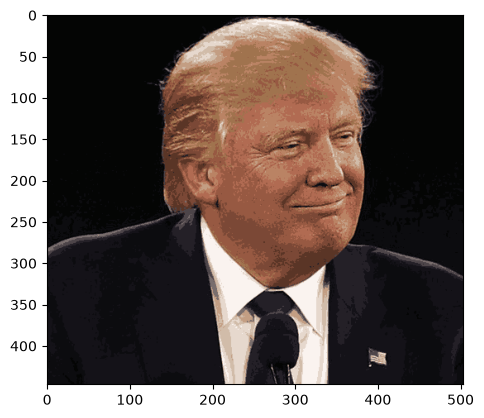

In [41]:
# display the new trump segmented 
trump_segmented = np.reshape(X_segmented, (w, h, d))

# affichage
plt.imshow(trump_segmented)

# Exercice 2 : clustering avec differents types de methodes pour l'indextion d'images
cet exercice est l'application d'une methode de clutering pour l'indexation d'images. il s'agit de voir ce que donne des methodes de clutering pour "ranger " des imagettes de chiffres de 0 a 9, sachant que cette methode est bien sur non supervisee (methode de classification donnerai de meilleurs resultats) mais il faut pour cela que l'on dispose d'une base d'apprentissage annotéé, ce qui est le cas ici.

le code pour charger les donnees:
- from sklearn.datasets import load_digits 
- digits = load_digits'
- data = digits.data
- # labels (pour le cas supervisé, et ici pour la comprehension / l'evaluation des resultats)
- targets = digits.target
- images = digits.images
- digits_nb, digits_dim = data.shape
- digits_class = len(np.unique(targets))
- size = int(np.sqrt(digits_dim))
- print("nombre d'imagettes=", digits_nb)
- print("dimension(images", sizen "x", sizen "pixels reshapées)=", digits_dim)
- print("nombre de chiffres de zeto a neuf=", digits_class)

Travail a faire: 
1. recopiez le code , commentez ligne par ligne
2. entrainer un modele de k-means avec autant de clusters 0-9
3. afficher les imagettes des centroides et verifiers que les clusters semblent bien representer les differents chiffres de 0 a9 
4. En etudiant la matrice de consiion, identifiez quel cluster correpond a quel chiffre.
5. recommencez les etapes 1 a 4 plsuieurs fois avec jmeans , que constatez vous ?
6. Point de valisation 1: recommenez les etapes 1 a 4, mais cettes fois ci avec la methoe de kmedoids de pyclustering, qui est une implementation de lago pam. Reiterez plusieurs fois. Quels sont les avantages et les inconvenients des k-medoides par rapport au k-means (repondre dans le notebook)

In [44]:
#  charger les données
from sklearn.datasets import load_digits 
digits = load_digits()
data = digits.data

In [ ]:
# from sklearn.datasets import load_digits

# data, labels = load_digits(return_X_y=True)
# (n_samples, n_features), n_digits = data.shape, np.unique(labels).size

# print(f"# digits: {n_digits}; # samples: {n_samples}; # features {n_features}")

# digits: 10; # samples: 1797; # features 64


1. commenter le code

In [ ]:
targets = digits.target # number of digits 0 to 9 for each digit, its the targets that are predicted
images = digits.images # retrieveing all images of shape (1797, 8, 8)
digits_nb, digits_dim = data.shape # nb is 1797 and dim is h= 8 and w=8 which is 64
digits_class = len(np.unique(targets)) # here its 0 to 9
size = int(np.sqrt(digits_dim)) # here its 8 because _= sqrt(64)
print("nombre d'imagettes=", digits_nb)
print("dimension (images", size, "x", size, "pixels reshapées)=", digits_dim)
print("nombre de chiffres de zeto a neuf=", digits_class)

nombre d'imagettes= 1797
dimension (images 8 x 8 pixels reshapées)= 64
nombre de chiffres de zeto a neuf= 10


In [60]:
size

8

In [57]:
images.shape

(1797, 8, 8)

In [59]:
len(targets)

1797

2. entrainer un modele de k-means avec autant de clusters 0-9

In [62]:
# entrainement de k-means 
from sklearn import cluster
kmeans = cluster.KMeans(n_clusters=10)  # 0 a 9 cest 10 clusters
kmeans.fit(data) # sur toutes les images qu'on a 


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",10
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](10, 64

In [ ]:
centroids_values = kmeans.cluster_centers_
print(centroids_values)


[[ 0.00000000e+00  1.58536585e-01  5.20121951e+00  1.17073171e+01
   1.25975610e+01  6.59146341e+00  5.24390244e-01  5.55111512e-17
   1.82926829e-02  1.96341463e+00  1.24024390e+01  1.15548780e+01
   9.47560976e+00  1.23414634e+01  2.68902439e+00 -4.16333634e-17
   4.33680869e-19  2.73780488e+00  1.11524390e+01  6.78658537e+00
   7.90853659e+00  1.26768293e+01  2.07926829e+00  6.93889390e-18
   2.16840434e-19  9.81707317e-01  7.89024390e+00  1.24939024e+01
   1.37621951e+01  7.01219512e+00  4.14634146e-01  4.33680869e-19
   0.00000000e+00  3.96341463e-01  6.95121951e+00  1.42500000e+01
   1.29207317e+01  3.78658537e+00  6.70731707e-02  0.00000000e+00
   1.73472348e-18  1.25000000e+00  1.12317073e+01  8.81097561e+00
   8.80487805e+00  8.04268293e+00  1.14634146e+00  6.93889390e-18
   1.82926829e-02  1.22560976e+00  1.15853659e+01  8.10365854e+00
   8.82317073e+00  9.69512195e+00  2.21341463e+00 -2.77555756e-17
   6.09756098e-03  1.76829268e-01  5.39024390e+00  1.26463415e+01
   1.30060

In [133]:
labels = kmeans.labels_
print(labels)

[6 2 2 ... 2 0 0]


In [136]:
labels_kmeans = labels


3. afficher les imagettes des centroides et verifiers que les clusters semblent bien representer les differents chiffres de 0 a9 


In [71]:
centroids_values.shape

(10, 64)

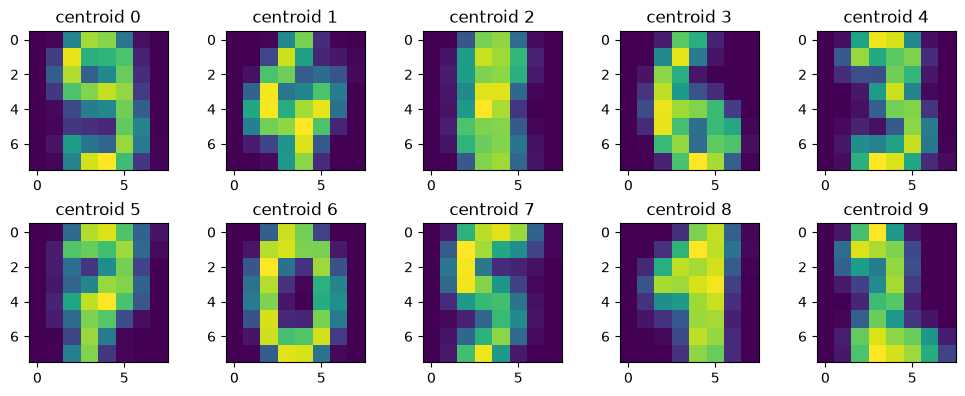

In [ ]:
plt.figure(figsize=(10, 4))

for i in range(10):
  plt.subplot(2, 5, i+1)  # 2 rows, 5 columns, i+1 for position in thee plot
  centroid_image = centroids_values[i].reshape(8, 8) # reshaping  because as shown above it contains 64 values
  plt.imshow(centroid_image)
  plt.title(f"centroid {i}")


plt.tight_layout()
plt.show()

#  k means is doing clustering with 10 clusters for data with images of diff digits
# to generate a new centroid : we calculate the mean of of all data points within that cluster
# to retrive the digit of that centroid, we take the closest point and display the digit image


4. En etudiant la matrice de consfusion, identifiez quel cluster correpond a quel chiffre.

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(targets, labels)

print(cm)
# ici on a targets dans les lignes et labels dans colonne
# exemple la ligNE 1 on voit le max 
# c'est 176 en colonne 4 --> c'est le cluster 3 (car on commence a partir de 0)
# le cluster 3 doit representer le 0 ( as shown above c'est correct!)


[[  0   0   0 176   0   2   0   0   0   0]
 [  1   1 130   0   1   0   2   0  23  24]
 [ 11   0   4   1  12   0   0   2 146   1]
 [  6   2   1   0 159   0   0   6   1   8]
 [  1   0   6   0   0 164   0  10   0   0]
 [  0 137   0   0   0   2   2   0   0  41]
 [  1   0   3   1   0   0 176   0   0   0]
 [  1   5   0   0   0   0   0 173   0   0]
 [142   5  11   0   0   0   1   2   3  10]
 [  1   6   1   0   1   3   0   8   0 160]]


On fait de meme pour le reste: 
- cluster 0: chiffre 8 --> car max 142 
- cluster 1: chiffre 5 --> max 137
- cluster 2: chiffre 1 max 130 
- cluster 3: chiffre 0 max 176 
- cluster 4: chiffre 3 max 159 
- cluster 5: chiffre 4 etc..
- cluster 6: chiffre 6 
- cluster 7: chiffre 7 
- cluster 8: chiffre 2 
- cluster 9: chiffre 9 


### repetition d'executions

5. recommencez les etapes 1 a 4 plsuieurs fois avec jmeans , que constatez vous ?


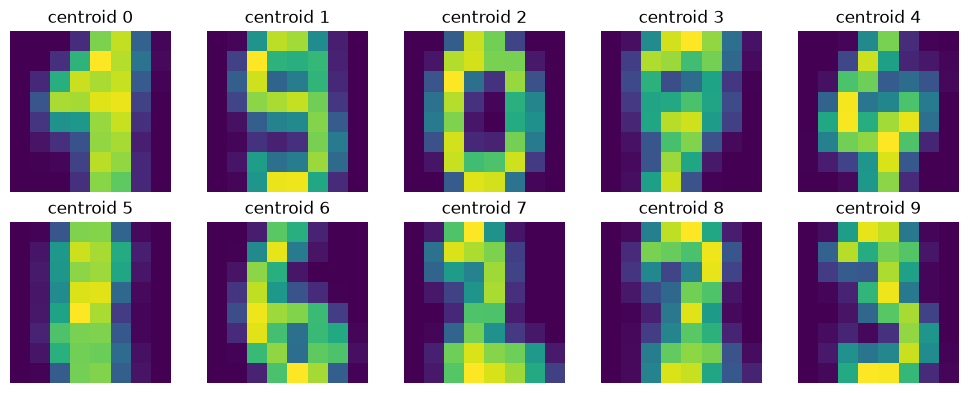

[[  0   0 177   0   1   0   0   0   0   0]
 [ 55   0   0   0   0 100   2  24   0   1]
 [  1   0   0   0   0   4   0 136  36   0]
 [  0   3   0   5   0   4   0   0  37 134]
 [  7   0   0   9 163   2   0   0   0   0]
 [  1  89   0  88   1   1   2   0   0   0]
 [  1   0   1   0   0   2 177   0   0   0]
 [  2   0   0 164   0  13   0   0   0   0]
 [  4  39   0  12   0  93   1   3  20   2]
 [ 20 132   0  12   0   0   0   0   3  13]]


In [91]:
targets = digits.target # number of digits 0 to 9 for each digit, its the targets that are predicted
images = digits.images # retrieveing all images of shape (1797, 8, 8)
digits_nb, digits_dim = data.shape # nb is 1797 and dim is h= 8 and w=8 which is 64
digits_class = len(np.unique(targets)) # here its 0 to 9
size = int(np.sqrt(digits_dim)) # here its 8 because _= sqrt(64)
# print("nombre d'imagettes=", digits_nb)
# print("dimension (images", size, "x", size, "pixels reshapées)=", digits_dim)
# print("nombre de chiffres de zeto a neuf=", digits_class)

# entrainement de k-means 
from sklearn import cluster
kmeans = cluster.KMeans(n_clusters=10)  # 0 a 9 cest 10 clusters
kmeans.fit(data) # sur toutes les images qu'on a 

centroids_values = kmeans.cluster_centers_
# print(centroids_values)

labels = kmeans.labels_
# print(labels)

plt.figure(figsize=(10, 4))

for i in range(10):
  plt.subplot(2, 5, i+1)  # 2 rows, 5 columns, i+1 for position in thee plot
  centroid_image = centroids_values[i].reshape(8, 8) # reshaping  because as shown above it contains 64 values
  plt.imshow(centroid_image)
  plt.axis('off')  # Hide the axis labels
  plt.title(f"centroid {i}")


plt.tight_layout()
plt.show()

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(targets, labels)

print(cm)
# ici on a targets dans les lignes et labels dans colonne


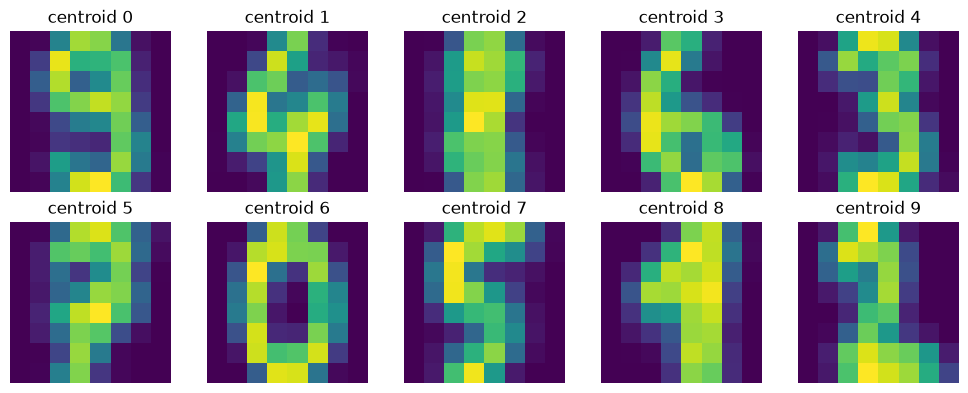

[[  0   1   0   0   0   0 177   0   0   0]
 [  0   0  99   2   1   0   0   1  55  24]
 [  2   0   8   0  13   3   1   0   2 148]
 [ 12   0   7   0 156   6   0   2   0   0]
 [  0 163   2   0   0   9   0   0   7   0]
 [ 42   1   0   1   1   0   0 137   0   0]
 [  0   0   2 177   0   0   1   0   1   0]
 [  0   0   2   0   0 170   0   5   2   0]
 [ 50   0 101   2   2   3   0   7   6   3]
 [139   0   0   0   6   8   0   7  20   0]]


In [92]:
targets = digits.target # number of digits 0 to 9 for each digit, its the targets that are predicted
images = digits.images # retrieveing all images of shape (1797, 8, 8)
digits_nb, digits_dim = data.shape # nb is 1797 and dim is h= 8 and w=8 which is 64
digits_class = len(np.unique(targets)) # here its 0 to 9
size = int(np.sqrt(digits_dim)) # here its 8 because _= sqrt(64)
# print("nombre d'imagettes=", digits_nb)
# print("dimension (images", size, "x", size, "pixels reshapées)=", digits_dim)
# print("nombre de chiffres de zeto a neuf=", digits_class)

# entrainement de k-means 
from sklearn import cluster
kmeans = cluster.KMeans(n_clusters=10)  # 0 a 9 cest 10 clusters
kmeans.fit(data) # sur toutes les images qu'on a 

centroids_values = kmeans.cluster_centers_
# print(centroids_values)

labels = kmeans.labels_
# print(labels)

plt.figure(figsize=(10, 4))

for i in range(10):
  plt.subplot(2, 5, i+1)  # 2 rows, 5 columns, i+1 for position in thee plot
  centroid_image = centroids_values[i].reshape(8, 8) # reshaping  because as shown above it contains 64 values
  plt.imshow(centroid_image)
  plt.axis('off')  # Hide the axis labels
  plt.title(f"centroid {i}")


plt.tight_layout()
plt.show()

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(targets, labels)

print(cm)
# ici on a targets dans les lignes et labels dans colonne


on constate que les labels des centroides changent et ceci car k-means n'est pas deterministe

ça revient au fait que les centroides sont choisis de façon random  --> solution : si on met random_state= fixed_value normalement on aura a chaque fois la mem execution

## K-medoids
6. Point de valisation 1: recommenez les etapes 1 a 4, mais cettes fois ci avec la methoe de kmedoids de pyclustering, qui est une implementation de lago pam. Reiterez plusieurs fois. Quels sont les avantages et les inconvenients des k-medoides par rapport au k-means (repondre dans le notebook)

2. entrainer un modele de k-means avec autant de clusters 0-9



In [100]:
from pyclustering.cluster.kmedoids import kmedoids

# we take 10 random unique medoids at first
initial_medoids = np.random.choice(len(data), 10, replace=False).tolist()
print(initial_medoids)


[943, 172, 1557, 374, 1079, 609, 532, 104, 1130, 749]


these are actual datapoints

In [101]:
# model initiliazation
kmedoids_model = kmedoids(data.tolist(), initial_medoids)
# training
kmedoids_model.process()


3. afficher les imagettes des centroides et verifiers que les clusters semblent bien representer les differents chiffres de 0 a9 


In [118]:
clusters = kmedoids_model.get_clusters()

medoids = kmedoids_model.get_medoids()
print("medoids :", medoids)


medoids : [339, 186, 1039, 983, 1327, 1417, 65, 1387, 1696, 1075]


In [123]:
for i in range(0,len(clusters)-1):
  print(f"cluster {i}")
  print(clusters[i])

cluster 0
[3, 13, 23, 45, 59, 60, 62, 63, 83, 89, 91, 98, 143, 175, 189, 190, 192, 193, 213, 217, 219, 220, 259, 264, 269, 279, 301, 315, 316, 318, 319, 339, 345, 347, 354, 359, 378, 385, 389, 399, 417, 423, 431, 445, 446, 448, 449, 459, 469, 475, 477, 484, 489, 491, 513, 529, 539, 555, 561, 578, 599, 605, 607, 614, 619, 623, 649, 659, 669, 691, 705, 706, 708, 709, 729, 735, 737, 744, 749, 779, 789, 799, 814, 816, 821, 835, 836, 838, 839, 859, 865, 867, 874, 879, 899, 913, 918, 923, 928, 933, 943, 947, 950, 955, 961, 962, 978, 992, 999, 1015, 1026, 1038, 1052, 1060, 1074, 1086, 1087, 1089, 1090, 1103, 1104, 1110, 1116, 1130, 1146, 1160, 1165, 1170, 1186, 1217, 1219, 1220, 1240, 1246, 1248, 1255, 1260, 1276, 1290, 1300, 1310, 1332, 1346, 1347, 1349, 1370, 1376, 1378, 1385, 1390, 1418, 1423, 1428, 1433, 1438, 1443, 1460, 1474, 1475, 1477, 1478, 1498, 1504, 1506, 1511, 1513, 1518, 1548, 1558, 1566, 1618, 1624, 1630, 1632, 1639, 1644, 1655, 1658, 1670, 1675, 1729, 1750, 1756, 1758, 1770, 1

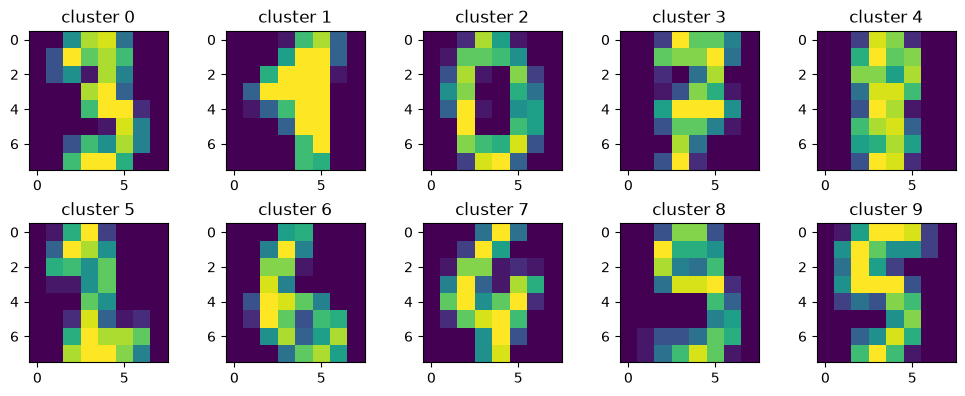

In [115]:
plt.figure(figsize=(10, 4))

for i, medoid_index in enumerate(medoids):
    plt.subplot(2, 5, i + 1)
    plt.imshow(data[medoid_index].reshape(8, 8))
    plt.title(f"cluster {i}")

plt.tight_layout()
plt.show()



4. En etudiant la matrice de consfusion, identifiez quel cluster correpond a quel chiffre.

In [131]:
labels = np.empty(len(data), dtype=int)

for cluster_index, cluster in enumerate(clusters):
    for i in cluster:
        labels[i] = cluster_index

In [132]:
labels_kmedoids = labels

In [ ]:
cm = confusion_matrix(targets, labels)
print(cm)

[[  0   0 176   0   0   0   0   2   0   0]
 [  2  55   0   0  99  23   3   0   0   0]
 [  3   1   1   3  24 136   0   0   9   0]
 [147   0   0  10   7   0   0   0  17   2]
 [  0   4   0   7   8   0   0 161   0   1]
 [  0   0   0   0   3   0   1   1  20 157]
 [  0   0   3   0   1   0 176   0   0   1]
 [  0   0   0 168   7   0   0   3   0   1]
 [ 21   6   2   2 125   4   3   0   5   6]
 [ 13  17   2   6   2   0   0   0 133   7]]


comme indiqué par exemple cluster 0 c'est le chiffre 3 car max = 147 a la ligne 4

### Réexecution

medoids : [65, 1696, 1417, 1387, 339, 1075, 1327, 1039, 983, 186]


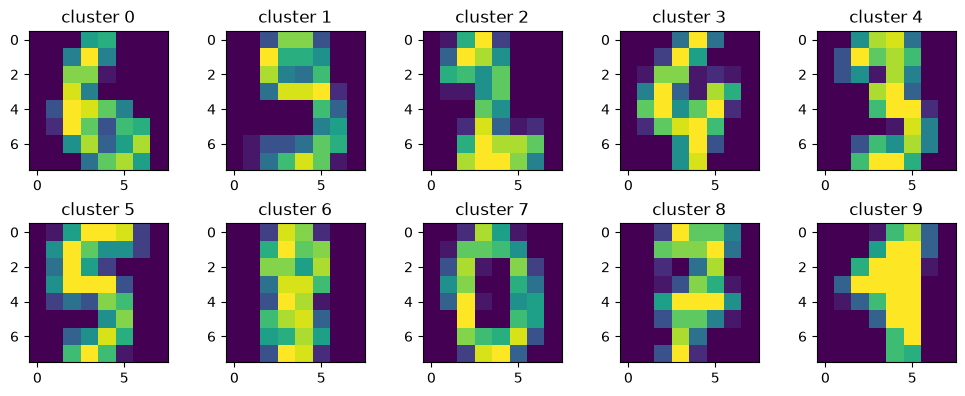

[[  0   0   0   2   0   0   0 176   0   0]
 [  3   0  23   0   2   0  99   0   0  55]
 [  0   9 136   0   3   0  24   1   3   1]
 [  0  17   0   0 147   2   7   0  10   0]
 [  0   0   0 161   0   1   8   0   7   4]
 [  1  20   0   1   0 157   3   0   0   0]
 [176   0   0   0   0   1   1   3   0   0]
 [  0   0   0   3   0   1   7   0 168   0]
 [  3   5   4   0  21   6 125   2   2   6]
 [  0 133   0   0  13   7   2   2   6  17]]


In [127]:
from pyclustering.cluster.kmedoids import kmedoids

# we take 10 random unique medoids at first
initial_medoids = np.random.choice(len(data), 10, replace=False).tolist()
# print(initial_medoids)
# model initiliazation
kmedoids_model = kmedoids(data.tolist(), initial_medoids)
# training
kmedoids_model.process()
clusters = kmedoids_model.get_clusters()
medoids = kmedoids_model.get_medoids()
print("medoids :", medoids)
plt.figure(figsize=(10, 4))

for i, medoid_index in enumerate(medoids):
    plt.subplot(2, 5, i + 1)
    plt.imshow(data[medoid_index].reshape(8, 8))
    plt.title(f"cluster {i}")

plt.tight_layout()
plt.show()
labels = np.empty(len(data), dtype=int)

for cluster_index, cluster in enumerate(clusters):
    for i in cluster:
        labels[i] = cluster_index

cm = confusion_matrix(targets, labels)
print(cm)

comme on  peut voir dans la deuxieme execution les medoids finaux sont differents

first exe : medoids : [339, 186, 1039, 983, 1327, 1417, 65, 1387, 1696, 1075]

second exe: medoids : [65, 1696, 1417, 1387, 339, 1075, 1327, 1039, 983, 186]


avantages:
  - le medoid is a real data point
  - more robust to outliers
  - we can use different distance metrics 

inconvenients:
  - takes more time if theres a lot of data --> computing distances each time between a point and all data points
  - takes random medoids so the execution changes every time

# 
7. point de validation 2: evaluers/ comparez la qualite des deux modeles construits a laide des metriques vues en cours; choissisez une mesure externe et deux mesures internes, et justifiez votre choix. 

In [137]:
from sklearn.metrics import homogeneity_score
from sklearn.metrics import silhouette_score
from sklearn.metrics import calinski_harabasz_score

homogeneity = homogeneity_score(targets, labels_kmeans)

silhouette = silhouette_score(data, labels_kmeans)

calinski = calinski_harabasz_score(data, labels_kmeans)

print("Homogeneity:", homogeneity)
print("Silhouette:", silhouette)
print("Calinski-Harabasz:", calinski)

Homogeneity: 0.7379591757607652
Silhouette: 0.18228185770488053
Calinski-Harabasz: 169.3611602841927


In [138]:
homogeneity = homogeneity_score(targets, labels_kmedoids)

silhouette = silhouette_score(data, labels_kmedoids)

calinski = calinski_harabasz_score(data, labels_kmedoids)

print("Homogeneity:", homogeneity)
print("Silhouette:", silhouette)
print("Calinski-Harabasz:", calinski)

Homogeneity: 0.7191608473463503
Silhouette: 0.17319163761752393
Calinski-Harabasz: 163.12687407475394


homogeneity : kmeans > kmedoids means that points of same label belong to same cluster

silouhette :  how similar an observation is to its own cluster (cohesion) compared to other clusters (separation) : kmeans > kmedoids

calinski-harabasz: C'est le rapport entre la variance inter-groupes et la variance intra-groupe.
kmeans > kmedoids
  

# 
8. point de validation 3: repeter les questions 1 a 5 avec une methode hierarchique, une grid-based et une density-based. vous pouvez utilieser ls methodes vues en cours, ou bien d'aures mais il faur que ça soit une par famille de methode. Comparer la qualite des differents modeles entrainés a laide des metriques que vous avez selectionnées. (repondre dans le notebook)

## Hierarchique

## grid-based

## density-based

In [150]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=30, min_samples=15)
labels_dbscan = dbscan.fit_predict(data)
print("Labels obtenus :", set(labels_dbscan))

Labels obtenus : {np.int64(0), np.int64(-1)}


## comparisons des valeurs de metriques

In [ ]:
# homogeneity = homogeneity_score(targets, labels_grid)

# silhouette = silhouette_score(data, labels_grid)

# calinski = calinski_harabasz_score(data, labels_grid)

# print("Homogeneity:", homogeneity)
# print("Silhouette:", silhouette)
# print("Calinski-Harabasz:", calinski)

In [143]:
homogeneity = homogeneity_score(targets, labels_dbscan)

silhouette = silhouette_score(data, labels_dbscan)

calinski = calinski_harabasz_score(data, labels_dbscan)

print("Homogeneity:", homogeneity)
print("Silhouette:", silhouette)
print("Calinski-Harabasz:", calinski)

Homogeneity: 0.0005649276657346004
Silhouette: -0.002273047545466552
Calinski-Harabasz: 0.9677923998073706


# 
9. quels sont les avantages et les inconvenients de chaque type de methode de clustering, que vous constatez avec ce tp? 